### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from query_history import query_history
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

### Data loading + appending with results from previous query

In [2]:
functions = {}

for i in range(1, 9):
    # Loading original data
    X = np.load(f"../initial_data/function_{i}/initial_inputs.npy")
    y = np.load(f"../initial_data/function_{i}/initial_outputs.npy")

    # Appending queries collected so far
    for query_X, query_y in query_history[i]:
        X = np.vstack([X, query_X])
        y = np.append(y, query_y)

    functions[i] = {
        "X": X,
        "y": y
    }

In [3]:
for i in range(1, 9):
    print(f"Function {i}: X = {functions[i]['X'].shape}, y = {functions[i]['y'].shape}")

Function 1: X = (14, 2), y = (14,)
Function 2: X = (14, 2), y = (14,)
Function 3: X = (19, 3), y = (19,)
Function 4: X = (34, 4), y = (34,)
Function 5: X = (24, 4), y = (24,)
Function 6: X = (24, 5), y = (24,)
Function 7: X = (34, 6), y = (34,)
Function 8: X = (44, 8), y = (44,)


### Reusable functions

In [4]:
def check_result(i):
    X, y = functions[i]["X"], functions[i]["y"]
    best = np.argmax(y)

    print(f"Function {i}")
    print(f"Latest: X={X[-1]}, y={y[-1]}")
    print(f"Best:   X={X[best]}, y={y[best]}")

In [5]:
def plot_2d(i, y=None):
    X = functions[i]["X"]
    y = functions[i]["y"] if y is None else y

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=80)
    plt.colorbar(label="Output")

    # Last week's query
    plt.scatter(X[-1, 0], X[-1, 1],
                marker="*", s=250, edgecolors="red",
                facecolors="none", linewidths=2,
                label="Last query")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}")
    plt.legend()
    plt.show()

In [6]:
kernels = {
    "RBF": RBF(0.1),
    "Matern": Matern(0.1, nu=2.5),
    "RQ": RationalQuadratic(length_scale=0.1, alpha=1.0)
}

length_scales = [0.05, 0.1, 0.2, 0.5]

def validate_kernels(i):
    X, y = functions[i]["X"], functions[i]["y"]
    results = {}

    for ls in length_scales:
        kernels = {
            "RBF": RBF(ls),
            "Matern": Matern(ls, nu=2.5),
            "RQ": RationalQuadratic(length_scale=ls, alpha=1.0)
        }

        for name, kernel in kernels.items():
            gp = GaussianProcessRegressor(
                kernel=kernel,
                normalize_y=True,
                optimizer=None
            )

            mae = -cross_val_score(
                gp, X, y,
                cv=LeaveOneOut(),
                scoring="neg_mean_absolute_error"
            ).mean()

            results[(name, ls)] = mae

    return sorted(results.items(), key=lambda x: x[1])

In [7]:
def fit_gp(i, kernel, transform=False):
    X, y = functions[i]["X"], functions[i]["y"]

    if transform:
        y = scale_scores(y)

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        optimizer=None
    )

    gp.fit(X, y)
    return gp

In [8]:
def plot_gp_2d(i, gp, suggestions=None):
    X = functions[i]["X"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    mean = gp.predict(X_grid)

    plt.contourf(x1, x2, mean.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predicted output")
    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")

    if suggestions:
        for name, point in suggestions.items():
            plt.scatter(*point, marker="X", s=120, label=name)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP predicted mean")
    plt.legend()
    plt.show()

In [24]:
def plot_gp_uncertainty_2d(i, gp):
    X = functions[i]["X"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    _, std = gp.predict(X_grid, return_std=True)

    plt.contourf(x1, x2, std.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predictive uncertainty (std)")
    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP uncertainty")
    plt.show()

In [9]:
def plot_3d(i, suggestions=None):
    X, y = functions[i]["X"], functions[i]["y"]

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    p = ax.scatter(X[:, 0], X[:, 1], X[:, 2],
                   c=y, cmap="viridis", s=70)

    # Last week's query
    ax.scatter(*X[-1], marker="*", s=300,
               edgecolors="red", facecolors="none",
               linewidths=2, label="Last week's query")

    if suggestions:
        for name, point in suggestions.items():
            ax.scatter(*point, marker="X", s=150, label=name)

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}")
    ax.legend()
    plt.colorbar(p, label="Output")
    plt.show()

In [10]:
def plot_3d_suggestions(i, suggestions):
    X = functions[i]["X"]
    y = functions[i]["y"]

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")

    # Existing observations
    p = ax.scatter(X[:,0], X[:,1], X[:,2], c=y, cmap="viridis", s=60)
    plt.colorbar(p, label="Output")

    # Acquisition suggestions
    markers = {"UCB": "^", "EI": "s", "PI": "X"}

    for name, point in suggestions.items():
        ax.scatter(
            point[0], point[1], point[2],
            marker=markers[name],
            s=180,
            label=name
        )

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}: Acquisition Suggestions")
    ax.legend()

    plt.show()

In [11]:
def acquisitions(gp, X_candidates, best_y, beta=1.96):
    mean, std = gp.predict(X_candidates, return_std=True)

    # UCB
    ucb = mean + beta * std

    # EI + PI
    improvement = mean - best_y
    z = improvement / (std + 1e-9)

    ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    pi = norm.cdf(z)

    return {
        "UCB": X_candidates[np.argmax(ucb)],
        "EI":  X_candidates[np.argmax(ei)],
        "PI":  X_candidates[np.argmax(pi)]
    }

In [12]:
def check_uncertainty(gp, suggestions):
    for name, point in suggestions.items():
        mean, std = gp.predict(point.reshape(1, -1), return_std=True)

        print(
            f"{name}: mean={mean[0]:.4f}, "
            f"uncertainty={std[0]:.4f}"
        )

In [13]:
def plot_scores(i):
    y = functions[i]["y"]
    positions = np.arange(len(y))
    best = np.argmax(y)

    plt.figure(figsize=(10, 5))
    plt.scatter(positions, y, s=70)

    # Label points with array position
    for pos, score in zip(positions, y):
        plt.annotate(str(pos), (pos, score),
                     xytext=(5, 5),
                     textcoords="offset points")

    # Last week's query
    plt.scatter(positions[-1], y[-1],
                marker="*", s=250,
                facecolors="none", edgecolors="red",
                linewidths=2, label="Last week's query")

    # Best observation
    plt.scatter(best, y[best],
                marker="X", s=200,
                label="Best score")

    plt.xlabel("Array position")
    plt.ylabel("Observed score")
    plt.title(f"Function {i}: Observed Scores")
    plt.legend()
    plt.show()

In [14]:
def uncertainty_search(gp, candidates, ranges):
    mean, std = gp.predict(candidates, return_std=True)

    for low, high in ranges:
        mask = (std >= low) & (std < high)

        if mask.any():
            idx = np.argmax(mean[mask])
            point = candidates[mask][idx]

            print(
                f"std {low:.2f}-{high:.2f}:",
                np.round(point, 3),
                f"mean={mean[mask][idx]:.3f}",
                f"std={std[mask][idx]:.3f}"
            )

In [15]:
def format_query(point):
    return "-".join(f"{v:.6f}" for v in point)

### Neural networks

This week's content introduces neural networks, so I want to explore whether they can provide any useful additional insights for my bbo strategy, particularly when modelling non-linear relationships and identifying influential input variables.

In [39]:
import tensorflow as tf

In [36]:
def build_nn(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(8, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

In [37]:
def train_nn(i, labels, hidden_size=8, epochs=1000, lr=0.01):
    X = functions[i]["X"].astype(np.float32)
    y = labels.astype(np.float32).reshape(-1, 1)

    input_size = X.shape[1]

    W1 = tf.Variable(
        tf.random.normal([input_size, hidden_size], stddev=0.1, seed=42)
    )
    b1 = tf.Variable(tf.zeros([hidden_size]))

    W2 = tf.Variable(
        tf.random.normal([hidden_size, 1], stddev=0.1, seed=42)
    )
    b2 = tf.Variable(tf.zeros([1]))

    def forward_pass(x):
        hidden = tf.nn.relu(tf.matmul(x, W1) + b1)
        logits = tf.matmul(hidden, W2) + b2
        output = tf.nn.sigmoid(logits)
        return output

    loss_fn = tf.keras.losses.BinaryCrossentropy()
    optimizer = tf.optimizers.SGD(learning_rate=lr)

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            y_pred = forward_pass(X)
            loss = loss_fn(y, y_pred)

        gradients = tape.gradient(
            loss, [W1, b1, W2, b2]
        )

        optimizer.apply_gradients(
            zip(gradients, [W1, b1, W2, b2])
        )

    return forward_pass, loss.numpy()

In [33]:
# Creates good/bad labels for NN classification
# Can use either a percentile or a manually chosen threshold

def create_labels(i, percentile=None, threshold=None):
    y = functions[i]["y"]

    if threshold is None:
        if percentile is None:
            percentile = 60
        threshold = np.percentile(y, percentile)

    labels = (y >= threshold).astype(np.float32)

    print(f"Function {i}")
    print(f"Threshold: {threshold}")
    print(f"Good observations: {int(np.sum(labels))}")
    print(f"Bad observations: {int(np.sum(labels == 0))}")

    return labels, threshold

In [43]:
def nn_loocv(i, labels, hidden_size=8, epochs=1000, lr=0.01):
    X = functions[i]["X"].astype(np.float32)
    labels = labels.astype(np.float32)

    predictions = []
    actual = []

    for test_idx in range(len(X)):
        # Leave one observation out
        train_mask = np.arange(len(X)) != test_idx

        X_train = X[train_mask]
        y_train = labels[train_mask].reshape(-1, 1)

        X_test = X[test_idx:test_idx + 1]
        y_test = int(labels[test_idx])

        # Build a new NN for this fold
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(X.shape[1],)),
            tf.keras.layers.Dense(hidden_size, activation="relu"),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

        model.compile(
            optimizer=tf.keras.optimizers.SGD(learning_rate=lr),
            loss="binary_crossentropy"
        )

        model.fit(
            X_train,
            y_train,
            epochs=epochs,
            verbose=0
        )

        # Probability of GOOD
        probability = model.predict(X_test, verbose=0)[0, 0]

        # >= 0.5 = GOOD
        predicted_class = int(probability >= 0.5)

        predictions.append(predicted_class)
        actual.append(y_test)

        print(
            f"Point {test_idx + 1}: "
            f"P(good)={probability:.3f}, "
            f"predicted={predicted_class}, "
            f"actual={y_test}"
        )

    predictions = np.array(predictions)
    actual = np.array(actual)

    accuracy = np.mean(predictions == actual)

    print(f"\nLOOCV accuracy: {accuracy:.3f}")

    return accuracy

In [39]:
def input_gradient(i, model):
    X = functions[i]["X"].astype(np.float32)
    y = functions[i]["y"]

    # Current best observed input
    best_x = X[np.argmax(y)]

    # Make input a TensorFlow variable so we can differentiate w.r.t. it
    x = tf.Variable(best_x.reshape(1, -1))

    with tf.GradientTape() as tape:
        prediction = model(x)

    gradient = tape.gradient(prediction, x).numpy()[0]

    print("Best point:", best_x)
    print("NN prediction:", prediction.numpy()[0, 0])
    print("Input gradients:", gradient)
    print(
        "Most influential input:",
        f"x{np.argmax(np.abs(gradient)) + 1}"
    )

    return gradient

### Function 1

In [16]:
check_result(1)

Function 1
Latest: X=[0.804414 0.7151  ], y=-2.766222565976174e-27
Best:   X=[0.73102363 0.73299988], y=7.710875114502849e-16


#### checking observation distribution

In [17]:
y = functions[1]["y"]

for value in np.sort(y):
    print(f"{value:.3e}")

-3.606e-03
-1.618e-05
-4.549e-20
-2.766e-27
-5.885e-49
-2.159e-54
-2.089e-91
3.342e-124
3.607e-81
1.323e-79
6.230e-48
1.033e-46
2.535e-40
7.711e-16


#### Visualising the data

using transformations to make sense of the data

In [18]:
from sklearn.preprocessing import QuantileTransformer

def scale_scores(y):
    qt = QuantileTransformer(
        n_quantiles=len(y),
        output_distribution="uniform"
    )
    return qt.fit_transform(y.reshape(-1, 1)).ravel()

[0.69230769 0.84615385 1.         0.53846036 0.         0.38461538
 0.46153846 0.92307692 0.61538462 0.76923077 0.30769231 0.15384615
 0.07692308 0.23076923]


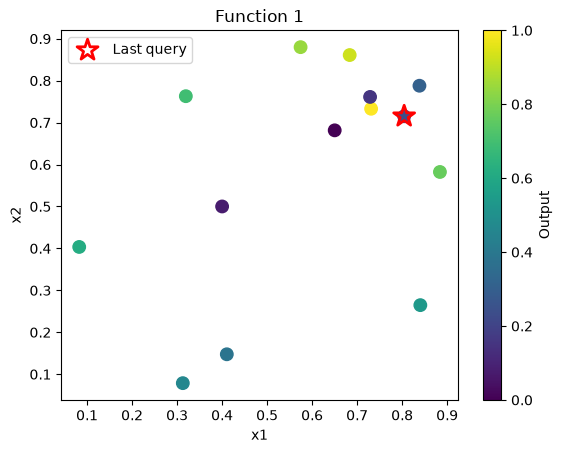

In [19]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, y_scaled)

#### chosen query for F1

`0.750000-0.870000`

Given how scattered the observations and results are, I think the most effective way to optimise F1 is through manual exploration of the search space. I considered training a neural network as a classifier to distinguish between good and bad regions, but with only two observations classified as ‘bad’ and the rest as ‘good’, the class imbalance would make the model unreliable. My GP hasn’t been particularly helpful either, so I think the most sensible strategy is to prioritise exploration with each query, then shift towards exploitation as we approach the end of the BBO process.

### Function 2

Function 2
Latest: X=[0.702637 1.      ], y=0.6710529877291967
Best:   X=[0.702637 1.      ], y=0.6710529877291967


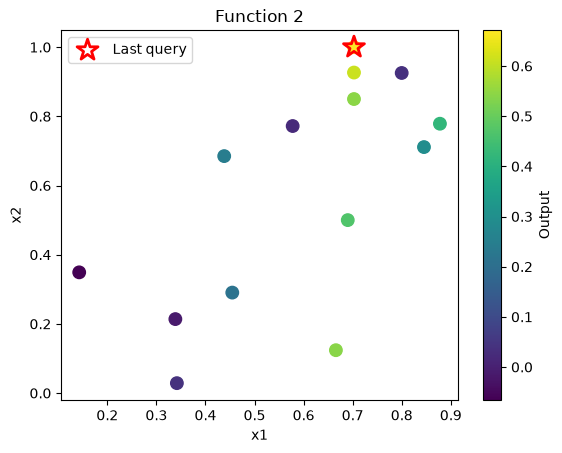

In [21]:
check_result(2)
plot_2d(2)

In [22]:
validate_kernels(2)

[(('Matern', 0.1), np.float64(0.20915102320736106)),
 (('RQ', 0.05), np.float64(0.2092986807518393)),
 (('RQ', 0.1), np.float64(0.21192592141213668)),
 (('RBF', 0.1), np.float64(0.2140265509289398)),
 (('RBF', 0.05), np.float64(0.21439981380328196)),
 (('Matern', 0.05), np.float64(0.21861925994942602)),
 (('Matern', 0.2), np.float64(0.24717561472354926)),
 (('RQ', 0.2), np.float64(0.26453519247758717)),
 (('Matern', 0.5), np.float64(0.3590492919866177)),
 (('RBF', 0.2), np.float64(0.45760138545172874)),
 (('RQ', 0.5), np.float64(0.7661052054664185)),
 (('RBF', 0.5), np.float64(1.849646848120559))]

In [23]:
best_kernel_f2 = Matern(length_scale=0.1)

gp_f2 = fit_gp(2, best_kernel_f2)

In [27]:
np.random.seed(42)
X_candidates = np.random.uniform(0, 1, (50000, 2))

best_y = functions[2]["y"].max()

In [28]:
suggestions = {}

for beta in [1.96, 3, 4]:
    result = acquisitions(
        gp_f2,
        X_candidates,
        best_y,
        beta=beta
    )

    suggestions[f"UCB β={beta}"] = result["UCB"]

    print(f"Beta {beta}: {result['UCB']}")

Beta 1.96: [0.63121781 0.98233327]
Beta 3: [0.60959157 0.99190149]
Beta 4: [0.59004819 0.9981298 ]


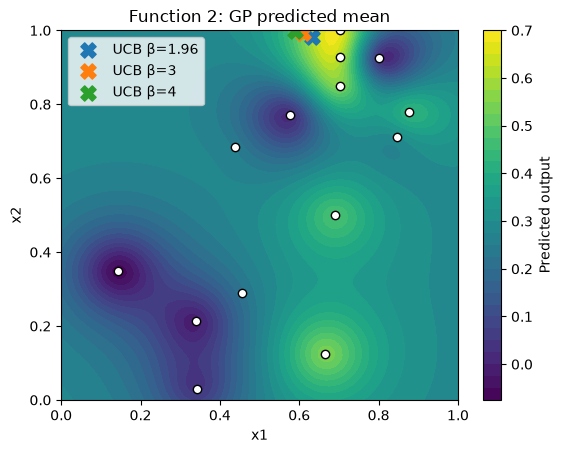

In [29]:
plot_gp_2d(2, gp_f2, suggestions)

Again the GP suggestions cluster around the best performing point, so I want to manually explore around another promising area around 0.67, 0.1.

#### chosen query for F2

`0.70263656, 0.10000000`

### Function 3

In [30]:
check_result(3)

Function 3
Latest: X=[0.213995 0.283284 0.400313], y=-0.03564707174254631
Best:   X=[0.181135 0.270895 0.418968], y=-0.027149095597068146


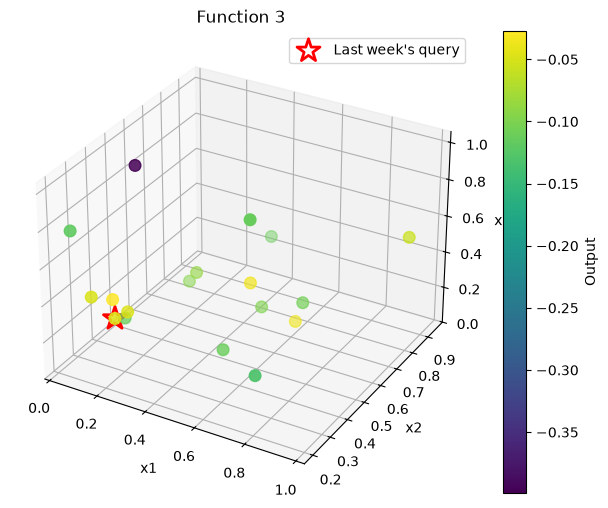

In [61]:
plot_3d(3)

#### checking points spread to support threshold for NN classifier

In [40]:
y = functions[3]["y"]

for value in np.sort(y):
    print(f"{value:.6f}")

-0.398926
-0.131461
-0.118048
-0.113869
-0.112122
-0.111415
-0.110621
-0.105965
-0.099521
-0.094190
-0.087963
-0.056758
-0.048008
-0.046947
-0.045230
-0.036378
-0.035647
-0.034835
-0.027149


In [41]:
labels_f3, threshold_f3 = create_labels(3, threshold=-0.06)

Function 3
Threshold: -0.06
Good observations: 8
Bad observations: 11


In [42]:
nn_f3, loss_f3 = train_nn(3, labels_f3)

print("Classification training loss:", loss_f3)

Classification training loss: 0.679407


In [44]:
accuracy_f3 = nn_loocv(3, labels_f3)

Point 1: P(good)=0.448, predicted=0, actual=0
Point 2: P(good)=0.456, predicted=0, actual=0
Point 3: P(good)=0.493, predicted=0, actual=0
Point 4: P(good)=0.349, predicted=0, actual=1
Point 5: P(good)=0.410, predicted=0, actual=1
Point 6: P(good)=0.405, predicted=0, actual=0
Point 7: P(good)=0.479, predicted=0, actual=0
Point 8: P(good)=0.516, predicted=1, actual=0
Point 9: P(good)=0.460, predicted=0, actual=0
Point 10: P(good)=0.400, predicted=0, actual=0
Point 11: P(good)=0.414, predicted=0, actual=1
Point 12: P(good)=0.407, predicted=0, actual=0
Point 13: P(good)=0.446, predicted=0, actual=0
Point 14: P(good)=0.328, predicted=0, actual=1
Point 15: P(good)=0.411, predicted=0, actual=1
Point 16: P(good)=0.448, predicted=0, actual=0
Point 17: P(good)=0.410, predicted=0, actual=1
Point 18: P(good)=0.459, predicted=0, actual=1
Point 19: P(good)=0.405, predicted=0, actual=1

LOOCV accuracy: 0.526


#### mini reflection on using an NN classifier

this function gave a fairly balanced split of 8 good and 11 bad observations, so i thought a NN classifier might work well here. however, LOOCV accuracy was only 52.6%, which is worse than the 57.9% accuracy achieved by simply predicting the majority ‘bad’ class every time. 

the NN predicted 18/19 observations as bad, meaning it had not learned a useful decision boundary. so, I will not use the classifier to select my next query - there is just too little data.

#### back to GP strategy

In [45]:
validate_kernels(3)

[(('Matern', 0.1), np.float64(0.038748991503168725)),
 (('RQ', 0.05), np.float64(0.03903921222478226)),
 (('RQ', 0.1), np.float64(0.03954298795477479)),
 (('RBF', 0.1), np.float64(0.04001679272728438)),
 (('RBF', 0.05), np.float64(0.0402802573320854)),
 (('Matern', 0.05), np.float64(0.04070968524768263)),
 (('Matern', 0.2), np.float64(0.045677082124098066)),
 (('RQ', 0.2), np.float64(0.05172292381311383)),
 (('RBF', 0.2), np.float64(0.0573724082736847)),
 (('Matern', 0.5), np.float64(0.07761101524021623)),
 (('RQ', 0.5), np.float64(0.11365715334018318)),
 (('RBF', 0.5), np.float64(0.17127942717963016))]

In [46]:
best_kernel_f3 = Matern(length_scale=0.1)
gp_f3 = fit_gp(3, best_kernel_f3)

In [47]:
X_candidates = np.random.uniform(0, 1, (50000, 3))

best_y_f3 = np.max(functions[3]["y"])

suggestions_f3 = acquisitions(
    gp_f3,
    X_candidates,
    best_y_f3
)

suggestions_f3

{'UCB': array([0.42550004, 0.52754512, 0.42206343]),
 'EI': array([0.1541448 , 0.21690339, 0.37314233]),
 'PI': array([0.18575348, 0.26122718, 0.39254171])}

In [48]:
check_uncertainty(gp_f3, suggestions_f3)

UCB: mean=-0.0746, uncertainty=0.0749
EI: mean=-0.0467, uncertainty=0.0554
PI: mean=-0.0297, uncertainty=0.0272


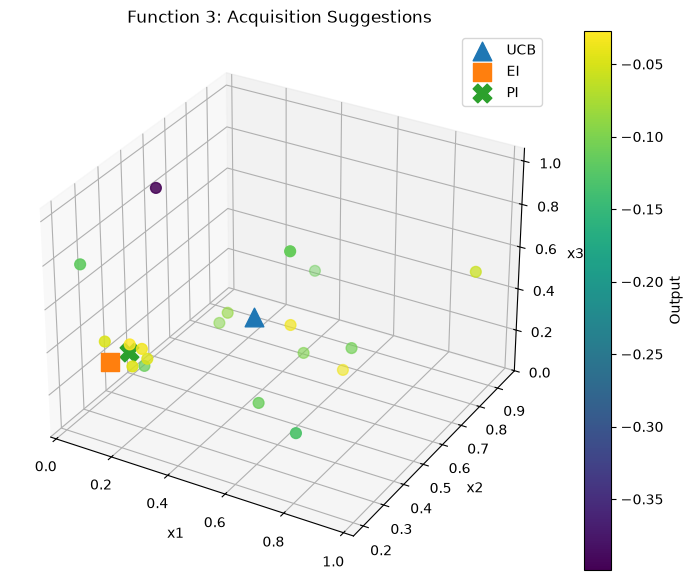

In [49]:
plot_3d_suggestions(3, suggestions_f3)

In [50]:
print(format_query(suggestions_f3["UCB"]))

0.425500-0.527545-0.422063


#### chosen query for F3

`0.425500-0.527545-0.422063`

The GP's PI and EI suggestions remained relatively close to the current best, whereas UCB suggested a much less explored point with high uncertainty. Since my best result came from exploration in Round 2 and local exploitation has not improved it in the last two rounds, I chose UCB to explore a different region this round.

### Function 4

the GP is having a consistently poor prediction performance although did reach a new best, so will explore around that region to improve again hopefully 

In [73]:
# seeing if the NN could give us some direction

nn_f4, loss_f4 = train_nn(4)
grad_f4 = input_gradient(4, nn_f4)

print("Training loss:", loss_f4)

Best point: [0.487016 0.438762 0.407357 0.365014]
NN prediction: -12.1884365
Input gradients: [ -7.2756004  -5.8199654  -2.3010178 -16.817135 ]
Most influential input: x4
Training loss: 24.871775


yeah...no

- Actual best: -1.0119
- NN prediction at that exact point: -12.1884
- Training loss: 24.87
  
even on a point it was trained on, it's predicting very badly. 

sooo I definitely won't be using these gradients to decide the query.

In [74]:
print(format_query([0.47, 0.43, 0.42, 0.38]))

0.470000-0.430000-0.420000-0.380000


Last week's query produced a new best, so will continue refining that region. I want to take a manual approach this time, seeing as the GP and NN are unreliable.

#### chosen query for F4

`0.470000-0.430000-0.420000-0.380000`

### Function 5

made another huge improvement so will continue working on refinement

In [76]:
check_result(5)
validate_kernels(5)

Function 5
Latest: X=[0.180065 1.       0.952231 0.889747], y=2735.7877787417397
Best:   X=[0.180065 1.       0.952231 0.889747], y=2735.7877787417397


[(('Matern', 0.5), np.float64(93.39699580341004)),
 (('RQ', 0.5), np.float64(95.7275373878981)),
 (('RQ', 0.2), np.float64(126.35824492873832)),
 (('Matern', 0.2), np.float64(188.62968403130913)),
 (('RBF', 0.5), np.float64(190.35795674565287)),
 (('RBF', 0.2), np.float64(192.89735295256926)),
 (('RQ', 0.1), np.float64(209.63372290635016)),
 (('RQ', 0.05), np.float64(297.5404445196656)),
 (('RBF', 0.1), np.float64(302.3946567544309)),
 (('Matern', 0.1), np.float64(307.88439432876646)),
 (('RBF', 0.05), np.float64(365.7867997123816)),
 (('Matern', 0.05), np.float64(377.07316154651943))]

In [77]:
best_kernel_f5 = Matern(length_scale=0.5, nu=2.5)

gp_f5 = fit_gp(5, best_kernel_f5)

In [78]:
best = functions[5]["X"][np.argmax(functions[5]["y"])]

rng = np.random.RandomState(42)
X_candidates_f5 = best + rng.uniform(-0.1, 0.1, (20000, 4)) # 0.1 to choose local search radius
X_candidates_f5 = np.clip(X_candidates_f5, 0, 1)

suggestions_f5 = acquisitions(
    gp_f5,
    X_candidates_f5,
    best_y=functions[5]["y"].max()
)

suggestions_f5

{'UCB': array([0.08119166, 1.        , 1.        , 0.98897716]),
 'EI': array([0.08119166, 1.        , 1.        , 0.98897716]),
 'PI': array([0.15497302, 1.        , 0.99862979, 0.9094787 ])}

In [79]:
check_uncertainty(gp_f5, suggestions_f5)

UCB: mean=3655.2393, uncertainty=160.8573
EI: mean=3655.2393, uncertainty=160.8573
PI: mean=3274.1219, uncertainty=50.0048


the GP is predicting really strong results again - I am leaning towards the more conservative PI acquisition this time 

In [80]:
print(format_query(suggestions_f5["PI"]))

0.154973-1.000000-0.998630-0.909479


#### chosen query for F5

`0.154973-1.000000-0.998630-0.909479`

### Function 6

In [81]:
check_result(6)
validate_kernels(6)

Function 6
Latest: X=[0.45433  0.363869 0.508315 0.757164 0.150167], y=-0.2049823948689158
Best:   X=[0.45433  0.363869 0.508315 0.757164 0.150167], y=-0.2049823948689158


[(('RQ', 0.5), np.float64(0.19086126103049367)),
 (('Matern', 0.5), np.float64(0.21996177138103007)),
 (('RBF', 0.5), np.float64(0.2274748673969925)),
 (('RQ', 0.2), np.float64(0.25348919214444976)),
 (('RBF', 0.2), np.float64(0.31295002833005814)),
 (('Matern', 0.2), np.float64(0.3135294244096335)),
 (('RQ', 0.1), np.float64(0.3427128965936922)),
 (('RBF', 0.1), np.float64(0.39905312567741297)),
 (('Matern', 0.1), np.float64(0.40619434424146106)),
 (('RQ', 0.05), np.float64(0.4110423812681623)),
 (('Matern', 0.05), np.float64(0.45012143947452726)),
 (('RBF', 0.05), np.float64(0.4529098449502109))]

In [82]:
best_kernel_f6 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f6 = fit_gp(6, best_kernel_f6)

#### exploiting around the promising region

In [83]:
best = functions[6]["X"][np.argmax(functions[6]["y"])]

rng = np.random.RandomState(42)

X_candidates_f6 = best + rng.uniform(
    -0.10, 0.10,
    (20000, 5)
)

X_candidates_f6 = np.clip(X_candidates_f6, 0, 1)

suggestions_f6 = acquisitions(
    gp_f6,
    X_candidates_f6,
    best_y=functions[6]["y"].max()
)

suggestions_f6

{'UCB': array([0.36398985, 0.29116573, 0.56569119, 0.85236367, 0.2409696 ]),
 'EI': array([0.41610158, 0.35307472, 0.52121045, 0.85618032, 0.20182727]),
 'PI': array([0.45687729, 0.3589992 , 0.53733449, 0.76865891, 0.17895546])}

In [84]:
check_uncertainty(gp_f6, suggestions_f6)

UCB: mean=-0.3206, uncertainty=0.1617
EI: mean=-0.2446, uncertainty=0.1081
PI: mean=-0.2016, uncertainty=0.0301


Local exploitation worked well last round, so I decided to continue refining the same promising region. However, I chose UCB this time because the GP has generally been pessimistic in its predictions, allowing for slightly more exploration despite the lower predicted mean.

In [85]:
print(format_query(suggestions_f6["UCB"]))

0.363990-0.291166-0.565691-0.852364-0.240970


#### chosen query for F6

`0.363990-0.291166-0.565691-0.852364-0.240970`

### Function 7

In [86]:
check_result(7)
validate_kernels(7)

Function 7
Latest: X=[0.14398  0.441215 0.207869 0.135499 0.348639 0.734274], y=1.5874438866096616
Best:   X=[0.14398  0.441215 0.207869 0.135499 0.348639 0.734274], y=1.5874438866096616


[(('RQ', 0.5), np.float64(0.16745698915952492)),
 (('Matern', 0.5), np.float64(0.17144758219581846)),
 (('RQ', 0.2), np.float64(0.1818160933744625)),
 (('RBF', 0.2), np.float64(0.2172746595480061)),
 (('Matern', 0.2), np.float64(0.2195805671160809)),
 (('RQ', 0.1), np.float64(0.22734261197253736)),
 (('Matern', 0.1), np.float64(0.26980738837463875)),
 (('RBF', 0.1), np.float64(0.27006640345209004)),
 (('RBF', 0.5), np.float64(0.27315293670024154)),
 (('RQ', 0.05), np.float64(0.27984954279249535)),
 (('RBF', 0.05), np.float64(0.31541028807078125)),
 (('Matern', 0.05), np.float64(0.3177459371890845))]

In [87]:
best_kernel_f7 = RationalQuadratic(length_scale=0.5)

gp_f7 = fit_gp(7, best_kernel_f7)

#### searching for unexplored region near the best 

In [88]:
from scipy.spatial.distance import cdist

best = functions[7]["X"][np.argmax(functions[7]["y"])]

rng = np.random.RandomState(42)
candidates = rng.uniform(0, 1, (50000, 6))

# Distance from current best
dist_best = np.linalg.norm(candidates - best, axis=1)

# staying around the best, but not getting too close
mask = (dist_best >= 0.15) & (dist_best <= 0.35)
local_candidates = candidates[mask]

mean, std = gp_f7.predict(local_candidates, return_std=True)
ucb = mean + 1.96 * std

idx = np.argmax(ucb)
query_f7 = local_candidates[idx]

print("Query:", query_f7)
print("Distance from best:", np.linalg.norm(query_f7 - best))
print("Predicted mean:", mean[idx])
print("Uncertainty:", std[idx])
print("UCB:", ucb[idx])

Query: [0.17416348 0.27010709 0.18208734 0.25950974 0.28208323 0.7181774 ]
Distance from best: 0.22565700837748445
Predicted mean: 1.65075862891526
Uncertainty: 0.14786337460971
UCB: 1.9405708431502915


Used UCB to explore around the known best region while enforcing a minimum distance from the current best. This avoids another very small local adjustment while retaining evidence from the strongest-performing region.

In [89]:
print(format_query(query_f7))

0.174163-0.270107-0.182087-0.259510-0.282083-0.718177


#### chosen query for F7

`0.174163-0.270107-0.182087-0.259510-0.282083-0.718177`

### Function 8

In [90]:
check_result(8)
validate_kernels(8)

Function 8
Latest: X=[0.144203 0.171262 0.       0.160866 0.48736  0.69414  0.404473 0.768492], y=9.7718024517176
Best:   X=[0.144203 0.171262 0.       0.160866 0.48736  0.69414  0.404473 0.768492], y=9.7718024517176


[(('RQ', 0.5), np.float64(0.3523252293800127)),
 (('RBF', 0.5), np.float64(0.4029309939088503)),
 (('Matern', 0.5), np.float64(0.42480298450109766)),
 (('RQ', 0.2), np.float64(0.5715693322792954)),
 (('RQ', 0.1), np.float64(0.7038038704568007)),
 (('Matern', 0.2), np.float64(0.7136337241574882)),
 (('RBF', 0.2), np.float64(0.7189910190492104)),
 (('RBF', 0.1), np.float64(0.7770629896789053)),
 (('Matern', 0.1), np.float64(0.7825809552905433)),
 (('RQ', 0.05), np.float64(0.784803823402305)),
 (('RBF', 0.05), np.float64(0.8250490068580014)),
 (('Matern', 0.05), np.float64(0.8292961912562625))]

In [91]:
best_kernel_f8 = RationalQuadratic(
    length_scale=0.5)

gp_f8 = fit_gp(8, best_kernel_f8)

In [92]:
best = functions[8]["X"][np.argmax(functions[8]["y"])]

rng = np.random.RandomState(42)
X_candidates_f8 = best + rng.uniform(-0.1, 0.1, (50000, 8))
X_candidates_f8 = np.clip(X_candidates_f8, 0, 1)

suggestions_f8 = acquisitions(
    gp_f8,
    X_candidates_f8,
    best_y=functions[8]["y"].max()
)

suggestions_f8

{'UCB': array([0.05112488, 0.2606222 , 0.08664117, 0.17400333, 0.39185213,
        0.59418037, 0.33813626, 0.67274047]),
 'EI': array([0.1707037 , 0.26656743, 0.07530202, 0.25765347, 0.53487724,
        0.59610081, 0.37316789, 0.685804  ]),
 'PI': array([0.10909193, 0.19693903, 0.07065173, 0.23069399, 0.46805361,
        0.660249  , 0.39731045, 0.7004213 ])}

In [93]:
check_uncertainty(gp_f8, suggestions_f8)

UCB: mean=9.7991, uncertainty=0.3758
EI: mean=9.8664, uncertainty=0.2905
PI: mean=9.8416, uncertainty=0.1944


In [94]:
print(format_query(suggestions_f8["EI"]))

0.170704-0.266567-0.075302-0.257653-0.534877-0.596101-0.373168-0.685804


#### final query choice for F8

`0.144203-0.171262-0.000000-0.160866-0.487360-0.694140-0.404473-0.768492`